In [1]:
import torch
from triton.testing import do_bench

DEVICE = torch.device("cuda:0")
torch.cuda.set_device(DEVICE)

N = 1 << 20
DTYPE = torch.float32
SEED = 42
WARMUP_MS = 25
REPEAT_MS = 100
RTOL = 1e-5
ATOL = 1e-6

In [2]:
%matplotlib inline

import sys
from pathlib import Path
import matplotlib.pyplot as plt

project_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "neuroslop" / "visualize_bench_results.py").is_file()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from neuroslop.visualize_bench_results import plot_benchmark

## Подгружаем CUDA C++ код

In [3]:
import os

os.environ["CUDA_HOME"] = "/usr/local/cuda-13.3"
os.environ["TORCH_CUDA_ARCH_LIST"] = "8.6"
os.environ["MAX_JOBS"] = "16"

from torch.utils.cpp_extension import load

cuda_module = load(
    name="cuda_vector_add",
    sources=[
        "/home/babanovil/ysda-dsl/01-vector-add/cuda_vector_add.cu"
    ],
    extra_cuda_cflags=["-O3"],
    verbose=True,
)

ninja: no work to do.


## Хелпер + компилируем CuTeDSL

In [4]:
import cutlass.cute as cute
from cutlass.cute.runtime import from_dlpack

import cute_vector_add

_add_cache = {}

# lets make hash for compiled function
def tensor_spec(t):
    return (t.device, t.dtype, tuple(t.shape), tuple(t.stride()))

def cute_add(x, y):
    out = torch.empty_like(x)

    key = tuple(tensor_spec(t) for t in (x, y, out))

    x_ = from_dlpack(x, assumed_align=16)
    y_ = from_dlpack(y, assumed_align=16)
    out_ = from_dlpack(out, assumed_align=16)

    compiled = _add_cache.get(key)
    if compiled is None:
        compiled = cute.compile(cute_vector_add.add, x_, y_, out_)
        _add_cache[key] = compiled

    compiled(x_, y_, out_)
    return out

In [5]:
def generate_inputs(n):
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    return tuple(
        torch.randn(n, device=DEVICE, dtype=DTYPE, generator=generator)
        for _ in range(2)
    )

In [6]:
import triton_vector_add

def torch_add(x, y):
    return torch.add(x, y)

def triton_add(x, y):
    return triton_vector_add.add(x, y)


# def implementation_v2(x, y):
    # TODO: paste your code
    # return torch.add(x, y)

In [7]:
# PASTE HERE YOU IMPLEMENTATIONS

IMPLEMENTATIONS = {
    "pytorch": torch_add,
    "triton": triton_add,
    "cuda": cuda_module.add,
    "cute": cute_add,
}

In [8]:
def verify(actual, expected):
    torch.testing.assert_close(actual, expected, rtol=RTOL, atol=ATOL)

In [9]:
def operation_counts(inputs, output):
    flops = inputs[0].numel()
    useful_bytes = sum(x.numel() * x.element_size() for x in inputs)
    useful_bytes += output.numel() * output.element_size()
    return flops, useful_bytes

In [10]:
def measure(fn, inputs, flops, useful_bytes):
    p20_ms, median_ms, p80_ms = do_bench(
        lambda: fn(*inputs),
        warmup=WARMUP_MS,
        rep=REPEAT_MS,
        quantiles=[0.2, 0.5, 0.8],
    )
    seconds = median_ms * 1e-3
    return {
        "median_us": median_ms * 1e3,
        "p20_us": p20_ms * 1e3,
        "p80_us": p80_ms * 1e3,
        "TFLOP/s": flops / seconds / 1e12,
        "effective_GB/s": useful_bytes / seconds / 1e9,
    }

In [11]:
@torch.no_grad()
def run_benchmark():
    with torch.cuda.device(DEVICE):
        inputs = generate_inputs(N)
        expected = torch_add(*inputs)
        flops, useful_bytes = operation_counts(inputs, expected)
        results = {}
        for name, fn in IMPLEMENTATIONS.items():
            fn_inputs = tuple(x.clone() for x in inputs)
            actual = fn(*fn_inputs)
            try:
                verify(actual, expected)
            except AssertionError as error:
                raise AssertionError(f"{name}: verification failed\n{error}") from error
            results[name] = measure(fn, fn_inputs, flops, useful_bytes)

    print(f"GPU: {torch.cuda.get_device_name(DEVICE)} | N={N} | dtype={DTYPE}")
    for name, metrics in results.items():
        speedup = results["pytorch"]["median_us"] / metrics["median_us"]
        print(
            f"{name:>16}: OK | {metrics['median_us']:.3f} us "
            f"(p20-p80: {metrics['p20_us']:.3f}-{metrics['p80_us']:.3f}) | "
            f"{metrics['TFLOP/s']:.6f} TFLOP/s | "
            f"{metrics['effective_GB/s']:.2f} effective GB/s | "
            f"{speedup:.2f}x"
        )
    return results

results = run_benchmark()

GPU: NVIDIA RTX A4000 | N=1048576 | dtype=torch.float32
         pytorch: OK | 35.840 us (p20-p80: 35.840-36.864) | 0.029257 TFLOP/s | 351.09 effective GB/s | 1.00x
          triton: OK | 37.888 us (p20-p80: 36.864-37.888) | 0.027676 TFLOP/s | 332.11 effective GB/s | 0.95x
            cuda: OK | 37.888 us (p20-p80: 37.888-38.912) | 0.027676 TFLOP/s | 332.11 effective GB/s | 0.95x
            cute: OK | 37.888 us (p20-p80: 37.485-38.912) | 0.027676 TFLOP/s | 332.11 effective GB/s | 0.95x


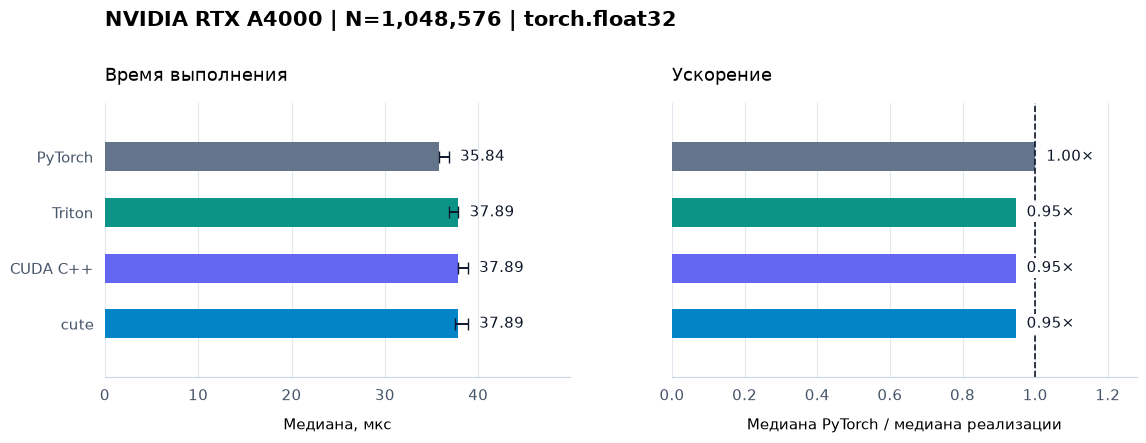

In [12]:
fig = plot_benchmark(
    results,
    title=f"{torch.cuda.get_device_name(DEVICE)} | N={N:,} | {DTYPE}",
)
plt.show()
